In [140]:
!pip install opencv-python
!pip install matplotlib
!pip install pandas

In [141]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from math import copysign, log10

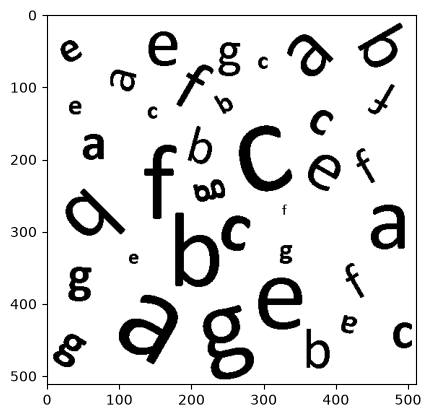

In [142]:
img = cv2.imread('sopa_letras.png', cv2.IMREAD_GRAYSCALE)


plt.figure()
plt.imshow(img, cmap='gray')
plt.show()

In [143]:
dimensions = img.shape 
print('Image Dimension: ',dimensions)

Image Dimension:  (512, 512)


In [144]:
#           v  -  h
letra1 = img[30:70,10:50]
letra2 = img[115:140,20:60]
letra3 = img[150:220,40:90]
letra4 = img[230:340,20:110]
letra5 = img[340:400,20:80]
letra6 = img[440:490,0:60]
letra7 = img[70:120,80:130]
letra8 = img[115:150,120:170]
letra9 = img[150:310,130:178]
letra10 = img[320:350,110:130]
letra11 = img[380:490,90:190]
letra12 = img[10:80,120:200]
letra13 = img[50:150,179:232]
letra14 = img[150:210,185:230]
letra15 = img[210:270,190:250]
letra16 = img[260:400,170:242]
letra17 = img[390:512,210:290]
letra18 = img[30:90,231:280]
letra19 = img[110:140,220:270]
letra20 = img[260:340,240:290]
letra21 = img[50:80,290:310]
letra22 = img[140:250,250:350]
letra23 = img[260:280,320:340]
letra24 = img[310:350,310:350]
letra25 = img[360:440,290:360]
letra26 = img[20:90,330:400]
letra27 = img[130:170,360:400]
letra28 = img[190:250,360:410]
letra29 = img[430:500,350:400]
letra30 = img[0:80,430:500]
letra31 = img[90:150,430:500]
letra32 = img[170:240,420:460]
letra33 = img[260:330,440:500]
letra34 = img[330:400,400:450]
letra35 = img[400:460,400:440]
letra36 = img[420:470,470:512]

letras = [] 
letras.append(letra1)
letras.append(letra2)
letras.append(letra3)
letras.append(letra4)
letras.append(letra5)
letras.append(letra6)
letras.append(letra7)
letras.append(letra8)
letras.append(letra9)
letras.append(letra10)
letras.append(letra11)
letras.append(letra12)
letras.append(letra13)
letras.append(letra14)
letras.append(letra15)
letras.append(letra16)
letras.append(letra17)
letras.append(letra18)
letras.append(letra19)
letras.append(letra20)
letras.append(letra21)
letras.append(letra22)
letras.append(letra23)
letras.append(letra24)
letras.append(letra25)
letras.append(letra26)
letras.append(letra27)
letras.append(letra28)
letras.append(letra29)
letras.append(letra30)
letras.append(letra31)
letras.append(letra32)
letras.append(letra33)
letras.append(letra34)
letras.append(letra35)
letras.append(letra36)




### Vemos que las imagenes ya estan binarizadas gracias a pasar la imagen a escala de grises
fondo = 255
objeto = 0

In [145]:
print(letra23)

[[255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255 255   0   0   0   0 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255   0   0 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255   0   0 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255   0   0 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255   0   0 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255   0   0 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255   0   0 255 255 255 255 255 255 255 255
  255 255]
 [255 255 255 255 255 255 255 255   0   0 255 255 255 255 255 255

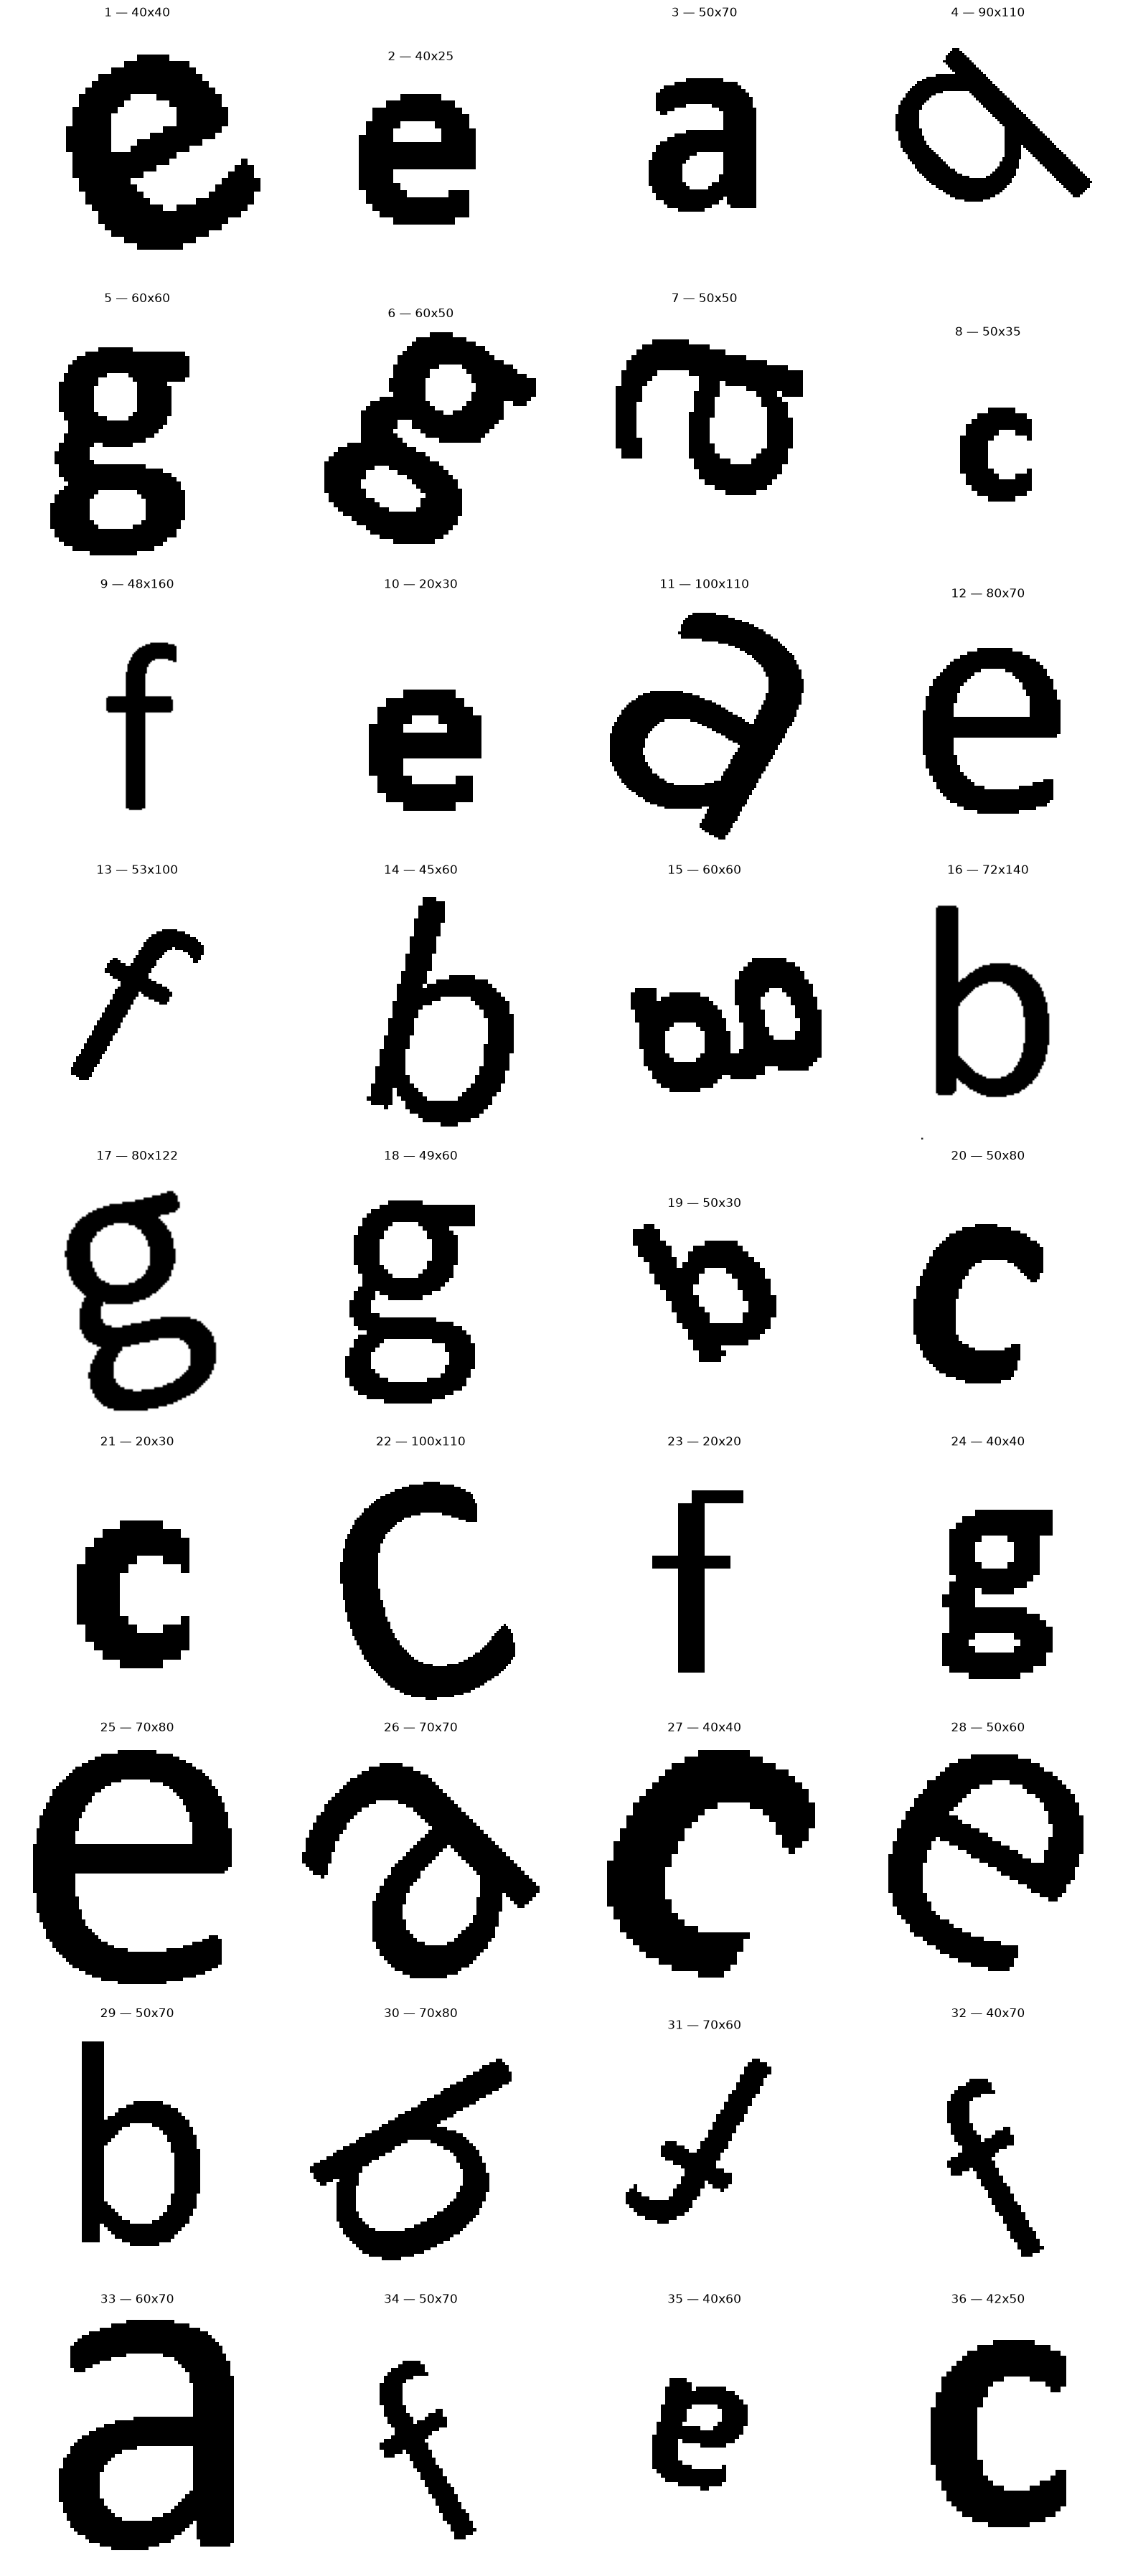

In [146]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Supongamos que 'imagenes' es una lista de arrays BGR de distintos tamaños
n = len(letras)
columnas = 4
filas = (n + columnas - 1) // columnas

fig, axes = plt.subplots(filas, columnas, figsize=(4 * columnas, 4 * filas))
axes = np.array(axes).flatten()  # por si es 2D o 1D

for i, img in enumerate(letras):
    img_rgb = img
    axes[i].imshow(img_rgb, cmap='gray')
    axes[i].set_title(f'{i+1} — {img.shape[1]}x{img.shape[0]}')
    axes[i].axis('off')

# Apagar los ejes sobrantes
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [147]:
#datosLetras = pd.DataFrame(columns = ['Hu1','Hu2','Hu3','Hu4','Perimetro','Redondez', 'Angulo de orientacion de elipse'])



#print(datosLetras)

In [148]:
def mrs(r, s, I, J):
    i=I**r
    j=J**s
    return np.sum(i*j)

In [149]:
def  m_central(r, s, I, J):
    m00 = mrs(0,0,I,J)
    m10 = mrs(1,0,I,J)
    m01 = mrs(0,1,I,J)

    ci = m10/m00
    cj = m01/m00
    i = (I-ci)**r
    j = (J-cj)**s

    return sum(i*j)

In [150]:
def eta(r, s, I, J):

    t = (r+s)/2 + 1
    a =  m_central(r,s,I,J)
    b =  m_central(0,0,I,J)

    return a/(b**t)

In [151]:
def hu(I, J):
    H= np.zeros(4)
    eta11 = eta(1,1,I,J)
    eta12 = eta(1,2,I,J)
    eta20 = eta(2,0,I,J)
    eta21 = eta(2,1,I,J)
    eta02 = eta(0,2,I,J)
    eta03 = eta(0,3,I,J)
    eta30 = eta(3,0,I,J)

    H[0] = eta20+eta02
    H[1] = (eta20-eta02)**2 + 4*eta11**2
    H[2] = (eta30-3*eta12)**2+(3*eta21-eta03)**2
    H[3] = (eta30+eta12)**2+(eta21+eta03)**2
    return H

Momentos de Hu normalizados para facilitar su analisis

In [152]:
cij = np.argwhere(letras[0]==0)


huMoments = hu(cij[:,0], cij[:,1])
#normalizamos los momentos
for i in range(0,4):
    huMoments[i] = -1* copysign(1.0, huMoments[i]) * log10(np.abs(huMoments[i]))
    print(huMoments[i])


0.5884104624422515
2.780459144478001
3.5594866171691932
3.79433344387855


In [153]:
listaDeMomentos = []
for i in range(0,36):
    cij = np.argwhere(letras[i]==0)
    huMoments = hu(cij[:,0], cij[:,1])
    for i in range(0,4):
        huMoments[i] = -1* copysign(1.0, huMoments[i]) * log10(np.abs(huMoments[i]))
    listaDeMomentos.append(huMoments)
print(listaDeMomentos)


[array([0.58841046, 2.78045914, 3.55948662, 3.79433344]), array([0.63822159, 3.04643174, 3.82888464, 4.18064164]), array([0.60137029, 2.50426707, 3.24106356, 4.13668564]), array([0.37599555, 1.59134507, 1.87325684, 3.1776579 ]), array([0.53032332, 1.6995634 , 3.36383135, 4.01476862]), array([0.53917707, 1.71705943, 3.3126983 , 3.99133489]), array([0.45088647, 1.97222533, 2.66644199, 3.25735614]), array([0.53447068, 1.98634206, 2.59891709, 3.06952724]), array([0.27196847, 0.66839742, 1.61969659, 2.0993094 ]), array([0.65457574, 3.28232596, 3.86153749, 4.09794941]), array([0.45289563, 1.98752103, 2.668536  , 3.33701207]), array([0.47220617, 2.40709338, 3.0404072 , 3.38987568]), array([0.2724651 , 0.67093046, 1.59823023, 2.09178393]), array([0.36975572, 1.5613802 , 1.85327715, 3.07116888]), array([0.5462092 , 1.74173978, 3.36997994, 4.10968134]), array([0.3681696 , 1.59936062, 1.82210733, 3.09939498]), array([0.40876333, 1.44191657, 2.84237625, 3.64045628]), array([0.43863621, 1.49271215,